# Бюллетень «Транспорт России»: примеры работы с базой

Тетрадка показывает, как работать с базой бюллетеня. В ней собраны все 53 выпуска
информационно-статистического бюллетеня Минтранса России за 2011–2025 годы:
- выпуски и их файлы;
- все таблицы выпусков и каждое число из них;
- ключевые ряды перевозок по видам транспорта;
- сверки итогов и пересмотров.

Схема и оговорки к данным — в [database.md](database.md).

Сборка и пакет `mintrans_stats` тетрадке не нужны. Если файла `data/bulletin.duckdb` нет,
та же база поднимается в памяти из таблиц Parquet (`data/parquet/`) по SQL из `sql/`. Нужны
пакеты `duckdb`, `pandas`, `matplotlib`, `jupyterlab`. Тетрадка работает и в репозитории
(`make venv && make notebook`), и в распакованном архиве `ru-mintrans-bulletins-parquet.zip`.

In [1]:
import re
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

# тетрадку можно открыть из корня репозитория (или распакованного архива) или из docs/
ROOT = Path.cwd() if (Path.cwd() / "data").is_dir() else Path.cwd().parent
DATA = ROOT / "data"
SQL = next(p for p in (ROOT / "sql", ROOT / "src" / "mintrans_stats" / "sql") if p.is_dir())


def open_bulletin() -> duckdb.DuckDBPyConnection:
    """Файл базы, если он есть, иначе та же база в памяти из таблиц Parquet."""
    if (DATA / "bulletin.duckdb").is_file():
        return duckdb.connect(str(DATA / "bulletin.duckdb"), read_only=True)
    con = duckdb.connect()
    schema = (SQL / "schema.sql").read_text(encoding="utf-8")
    con.execute(schema)
    for table in re.findall(r"^CREATE TABLE (\w+)", schema, flags=re.MULTILINE):
        con.execute(f"INSERT INTO {table} SELECT * FROM '{DATA / 'parquet' / table}.parquet'")
    con.execute((SQL / "views.sql").read_text(encoding="utf-8"))
    con.execute((SQL / "comments.sql").read_text(encoding="utf-8"))
    return con


con = open_bulletin()
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)
con.sql("SELECT * FROM build_info").df()

,key,value
0,built_at,2026-11-03T17:10:15Z
1,mintrans_stats_version,0.2.0
2,duckdb_version,2.0.0
3,source,https://mintrans.gov.ru/ministry/results/180/documents
4,periods,2011-01..12 — 2025-01..09
5,rows.issues,53
6,rows.files,54
7,rows.source_tables,2143
8,rows.table_values,95434
9,rows.core_observations,3292


## 1. Что в базе

Описания таблиц и представлений хранятся в самой базе (`COMMENT ON`).

В DuckDB 2.0 у результата `con.sql(...)` нет `fetchone()`: для одного значения
используйте `con.execute(...).fetchone()`, для таблицы — `.df()`.

In [2]:
con.sql("""
    SELECT table_name AS name, 'таблица' AS kind, estimated_size AS rows, comment
    FROM duckdb_tables()
    UNION ALL
    SELECT view_name, 'представление', NULL, comment
    FROM duckdb_views() WHERE NOT internal
    ORDER BY kind DESC, name
""").df()

,name,kind,rows,comment
0,build_info,таблица,12,Сведения о сборке базы
1,checks,таблица,1578,Проверки: total_vs_sum — итог против суммы видов; revision — пересмотры межд...
2,core_observations,таблица,3292,"Ключевые показатели из всех выпусков, с повторами одного периода"
3,core_series,таблица,1912,Ключевые ряды без повторов: значение из самого позднего выпуска
4,files,таблица,54,"Файлы выпусков (doc, docx, pdf, rar), скачанные с сайта"
5,indicators,таблица,4,Ключевые показатели: перевозки и обороты пассажиров и грузов
6,issues,таблица,53,Выпуски бюллетеня: один документ сайта — один выпуск за период нарастающим и...
7,source_tables,таблица,2143,"Таблицы, извлечённые из файлов; CSV лежит в data/tables"
8,table_values,таблица,95434,Каждая числовая ячейка каждой таблицы всех выпусков
9,transport_modes,таблица,15,"Виды транспорта; mode_group: total — итоги, mintrans — отрасли Минтранса, ot..."


In [3]:
# столбцы таблицы с их описаниями
con.sql("""
    SELECT column_name, data_type, comment
    FROM duckdb_columns() WHERE table_name = 'table_values'
""").df()

,column_name,data_type,comment
0,document_id,INTEGER,NaN
1,report_period,VARCHAR,NaN
2,report_year,INTEGER,NaN
3,report_month_to,INTEGER,NaN
4,table_id,VARCHAR,NaN
5,location,VARCHAR,NaN
6,caption,VARCHAR,NaN
7,topic,VARCHAR,"Ключевой показатель, если таблица сводная по видам транспорта"
8,unit,VARCHAR,NaN
9,row_index,INTEGER,NaN


## 2. Выпуски

Выпуски выходят нарастающим итогом: I квартал (`01..03`), полугодие (`01..06`),
9 месяцев (`01..09`) и год (`01..12`). Один выпуск (январь–сентябрь 2017) есть только в
поиске по сайту, а не в разделе «Статистика»: у него `in_section = false`.

In [4]:
con.sql("""
    SELECT report_year,
           string_agg(lpad(month_to::VARCHAR, 2, '0'), ' ' ORDER BY month_to) AS months_to,
           count(*) AS issues
    FROM issues GROUP BY report_year ORDER BY report_year
""").df()

,report_year,months_to,issues
0,2011,12,1
1,2012,06 09 12,3
2,2013,03 06 09 12,4
3,2014,03 06 09 12,4
4,2015,03 06 09 12,4
5,2016,03 06 09 12,4
6,2017,03 06 09,3
7,2018,03 06 09 12,4
8,2019,03 06 09 12,4
9,2020,03 06 09,3


In [5]:
con.sql("""
    SELECT document_id, report_period, published_at, in_section, title, url
    FROM issues ORDER BY report_period DESC LIMIT 5
""").df()

,document_id,report_period,published_at,in_section,title,url
0,15038,2025-01..09,2025-12-11,True,ТРАНСПОРТ РОССИИ. Информационно-статистический бюллетень. 9 месяцев 2025 года,https://mintrans.gov.ru/documents/7/15038
1,14772,2025-01..06,2025-09-08,True,ТРАНСПОРТ РОССИИ. Информационно-статистический бюллетень. I полугодие 2025 года,https://mintrans.gov.ru/documents/7/14772
2,14478,2025-01..03,2025-06-09,True,ТРАНСПОРТ РОССИИ. Информационно-статистический бюллетень. 1 квартал 2025 года,https://mintrans.gov.ru/documents/7/14478
3,14303,2024-01..12,2025-03-14,True,ТРАНСПОРТ РОССИИ. Информационно-статистический бюллетень. 2024 год,https://mintrans.gov.ru/documents/7/14303
4,13999,2024-01..09,2024-12-05,True,ТРАНСПОРТ РОССИИ. Информационно-статистический бюллетень. 9 месяцев 2024 года,https://mintrans.gov.ru/documents/7/13999


## 3. Ключевые ряды: перевозки грузов по видам транспорта

Представление `annual_series` — годовые значения четырёх ключевых показателей по видам
транспорта. Для каждого периода в базе стоит значение из самого позднего выпуска, то есть
последний пересмотр.

In [6]:
freight = con.sql("""
    PIVOT (
        SELECT year, mode, value FROM annual_series
        WHERE indicator = 'freight_carried'
          AND mode IN ('total', 'total_mintrans', 'rail', 'road', 'pipeline', 'sea',
                       'inland_water', 'air')
    )
    ON mode USING first(value)
    ORDER BY year
""").df().set_index("year")
freight

,air,inland_water,pipeline,rail,road,sea,total,total_mintrans
year,,,,,,,,
2010,0.900,102.40,1061.5,1205.8,5236.4,37.00,10916.2,9854.7
2011,0.981,127.80,1130.9,1241.5,5663.1,33.90,11534.8,10403.9
2012,0.988,140.50,1096.4,1271.9,5841.6,18.35,11635.6,10539.2
2013,1.001,134.86,1095.2,1236.8,5635.3,16.74,11273.1,10177.9
2014,1.036,118.93,1076.8,1226.9,5414.4,15.26,10981.3,9904.5
2015,1.060,118.42,1071.0,1217.9,5040.6,18.28,10518.8,9447.8
2016,0.970,113.77,1088.0,1227.0,5138.2,23.84,10664.7,9576.7
2017,1.174,118.53,1138.2,1266.5,5447.0,26.39,7997.8,6859.6
2018,1.180,116.20,1169.3,1291.5,5544.4,23.20,8145.8,6976.5


График строится в стиле, общем для всех графиков тетрадки:
- тонкие линии;
- приглушённые оси и сетка;
- подпись у конца каждой линии, а не только в легенде.

Цвета взяты в фиксированном порядке из проверенной палитры. Её проверили на различимость
при нарушениях цветового зрения.

In [7]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a"]  # синий, оранжевый, бирюзовый — в этом порядке
INK, INK_2, MUTED, GRID, AXIS, SURFACE = (
    "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
)
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10, "font.family": "sans-serif",
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.grid": True, "axes.grid.axis": "y",
    "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2,
    "ytick.labelcolor": INK_2, "ytick.left": False,
    "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "legend.frameon": False, "legend.labelcolor": INK_2,
})


def label_line_ends(ax, df, colors, fmt="{:,.0f}", min_gap=0.06):
    """Подпись у конца каждой линии: название и последнее значение.

    Близкие подписи раздвигаются по вертикали (min_gap — доля высоты оси), точка остаётся
    на своём значении.
    """
    ends = []
    for (name, series), color in zip(df.items(), colors):
        last = series.dropna()
        ends.append([last.iloc[-1], last.index[-1], name, color, last.iloc[-1]])
    low, high = ax.get_ylim()
    gap = (high - low) * min_gap
    ends.sort(key=lambda e: e[0])
    clusters = [[ends[0]]]
    for cur in ends[1:]:
        prev = clusters[-1][-1]
        if cur[0] < prev[0] + gap:
            clusters[-1].append(cur)
        else:
            clusters.append([cur])
    for cluster in clusters:  # близкие подписи — веером вокруг их среднего значения
        middle = sum(e[4] for e in cluster) / len(cluster)
        for k, e in enumerate(cluster):
            e[0] = middle + (k - (len(cluster) - 1) / 2) * gap
    for y_text, x, name, color, y in ends:
        ax.plot(x, y, "o", color=color, markersize=6, markeredgecolor=SURFACE,
                markeredgewidth=2, zorder=3)
        ax.text(x + 0.4, y_text, f"{name}  {fmt.format(y).replace(',', ' ')}",
                va="center", color=INK_2, fontsize=9)

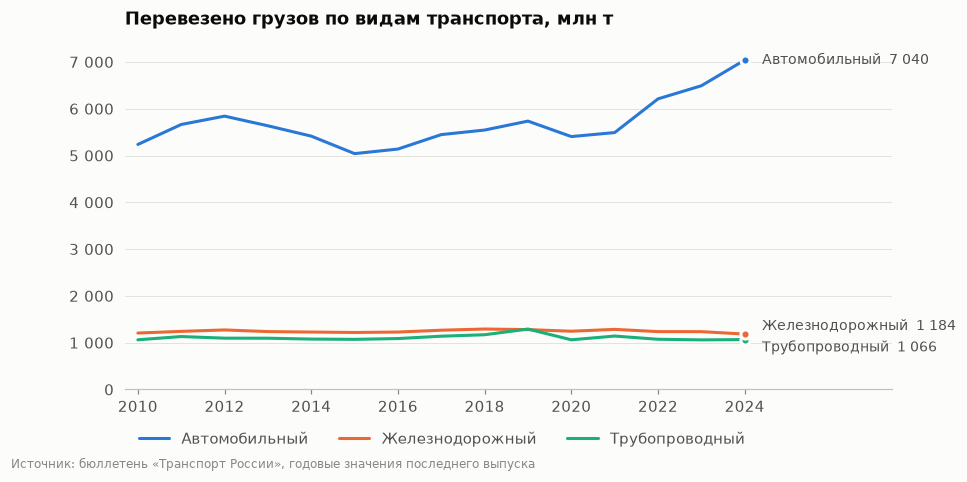

In [8]:
names = dict(con.sql("SELECT mode, name FROM transport_modes").fetchall())
short = {"road": "Автомобильный", "rail": "Железнодорожный", "pipeline": "Трубопроводный"}
plot = freight[["road", "rail", "pipeline"]].rename(columns=short)

fig, ax = plt.subplots(figsize=(9, 4.2))
for (name, series), color in zip(plot.items(), SERIES):
    ax.plot(series.index, series.values, color=color, label=name)
ax.set_title("Перевезено грузов по видам транспорта, млн т")
ax.set_xlim(plot.index.min() - 0.3, plot.index.max() + 3.4)
ax.set_ylim(0, plot.max().max() * 1.08)
label_line_ends(ax, plot, SERIES)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
ax.set_xticks(range(2010, 2025, 2))
ax.legend(loc="upper left", ncols=3, bbox_to_anchor=(0, -0.08))
fig.text(0.01, -0.06, "Источник: бюллетень «Транспорт России», годовые значения "
         "последнего выпуска", color=MUTED, fontsize=8)
plt.show()

## 4. Оговорка: состав итогов менялся

Итоги грузовых таблиц в 2017 году падают примерно на 2,7 млрд т. Падают оба: «Транспорт
всех отраслей экономики» (`total`) и «Транспорт отраслей Минтранса России»
(`total_mintrans`). Причина не в спаде перевозок: до выпусков за 2016 год в итоги входил
промышленный железнодорожный транспорт (`rail_industrial`, около 3 млрд т в год), с 2017
года — нет. Сопоставимый ряд — итог отраслей Минтранса без промышленного транспорта; он
совпадает с суммой видов. Перед сравнением итогов разных лет проверяйте состав и `checks`.

In [9]:
totals = con.sql("""
    SELECT year,
           max(value) FILTER (mode = 'total_mintrans') AS published,
           max(value) FILTER (mode = 'rail_industrial') AS rail_industrial,
           published - coalesce(rail_industrial, 0) AS comparable,
           sum(value) FILTER (mode IN ('rail', 'road', 'sea', 'inland_water', 'air'))
               AS sum_of_modes
    FROM annual_series WHERE indicator = 'freight_carried'
    GROUP BY year ORDER BY year
""").df().set_index("year").round(1)
totals

,published,rail_industrial,comparable,sum_of_modes
year,,,,
2010,9854.7,3272.2,6582.5,6582.5
2011,10403.9,3338.1,7065.8,7067.3
2012,10539.2,3265.9,7273.3,7273.3
2013,10177.9,3153.2,7024.7,7024.7
2014,9904.5,3128.0,6776.5,6776.5
2015,9447.8,3051.5,6396.3,6396.3
2016,9576.7,3072.9,6503.8,6503.8
2017,6859.6,NaN,6859.6,6859.6
2018,6976.5,NaN,6976.5,6976.5


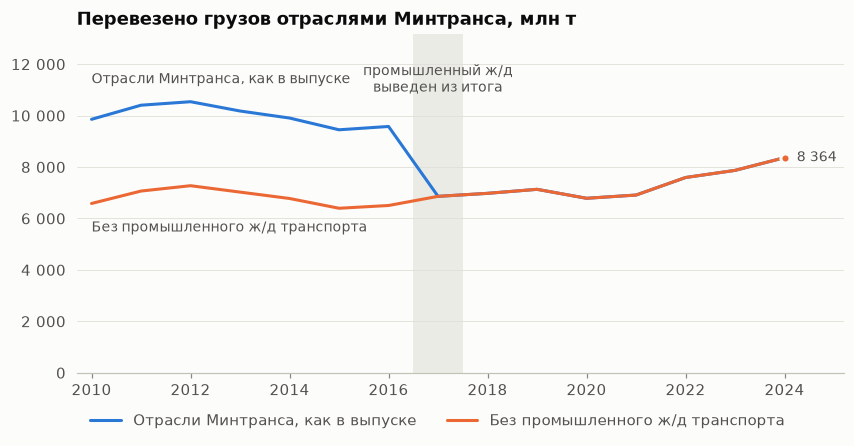

In [10]:
plot = totals[["published", "comparable"]].rename(columns={
    "published": "Отрасли Минтранса, как в выпуске",
    "comparable": "Без промышленного ж/д транспорта",
})
fig, ax = plt.subplots(figsize=(9, 4))
for (name, series), color in zip(plot.items(), SERIES):
    ax.plot(series.index, series.values, color=color, label=name)
# с 2017 года ряды совпадают, поэтому подписи стоят у начала линий
for (name, series), color, dy in zip(plot.items(), SERIES, (26, -16)):
    ax.annotate(name, (series.index[0], series.iloc[0]), xytext=(0, dy),
                textcoords="offset points", color=INK_2, fontsize=9, va="center")
ax.axvspan(2016.5, 2017.5, color=GRID, alpha=0.6, linewidth=0)
ax.annotate("промышленный ж/д\nвыведен из итога", (2017, plot.max().max() * 1.02),
            color=INK_2, fontsize=9, ha="center", va="bottom")
last = plot.iloc[-1, 0]
ax.plot(plot.index[-1], last, "o", color=SERIES[1], markersize=6, markeredgecolor=SURFACE,
        markeredgewidth=2, zorder=3)
ax.annotate(f"{last:,.0f}".replace(",", " "), (plot.index[-1], last), xytext=(8, 0),
            textcoords="offset points", va="center", color=INK_2, fontsize=9)
ax.set_title("Перевезено грузов отраслями Минтранса, млн т")
ax.set_xlim(plot.index.min() - 0.3, plot.index.max() + 1.2)
ax.set_ylim(0, plot.max().max() * 1.25)
ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}".replace(",", " "))
ax.set_xticks(range(2010, 2025, 2))
ax.legend(loc="upper left", ncols=2, bbox_to_anchor=(0, -0.08))
plt.show()

## 5. Темп роста: пассажирооборот авиации

Оконные функции считают изменение к прошлому году прямо в SQL.

In [11]:
con.sql("""
    SELECT year, value AS bln_pkm,
           round(100 * (value / lag(value) OVER (ORDER BY year) - 1), 1) AS yoy_pct
    FROM annual_series
    WHERE indicator = 'passenger_turnover' AND mode = 'air'
    ORDER BY year
""").df().set_index("year")

,bln_pkm,yoy_pct
year,,
2010,147.1,NaN
2011,166.8,13.4
2012,195.8,17.4
2013,225.2,15.0
2014,241.4,7.2
2015,226.8,-6.0
2016,215.3,-5.1
2017,259.4,20.5
2018,286.9,10.6


## 6. Кварталы из нарастающего итога

Значение за `2024-01..06` — это январь–июнь. Квартал — разность соседних периодов одного
года.

In [12]:
quarters = con.sql("""
    SELECT year, month_to // 3 AS quarter, value AS cumulative,
           round(value - coalesce(lag(value) OVER (PARTITION BY year ORDER BY month_to), 0), 1)
               AS quarter_value
    FROM series
    WHERE indicator = 'freight_turnover' AND mode = 'rail' AND year BETWEEN 2021 AND 2024
    ORDER BY year, month_to
""").df()
quarters

,year,quarter,cumulative,quarter_value
0,2021,1,635.2,635.2
1,2021,2,1303.6,668.4
2,2021,3,1960.1,656.5
3,2021,4,2639.4,679.3
4,2022,1,660.5,660.5
5,2022,2,1319.7,659.2
6,2022,3,1968.9,649.2
7,2022,4,2637.8,668.9
8,2023,1,677.9,677.9
9,2023,2,1338.5,660.6


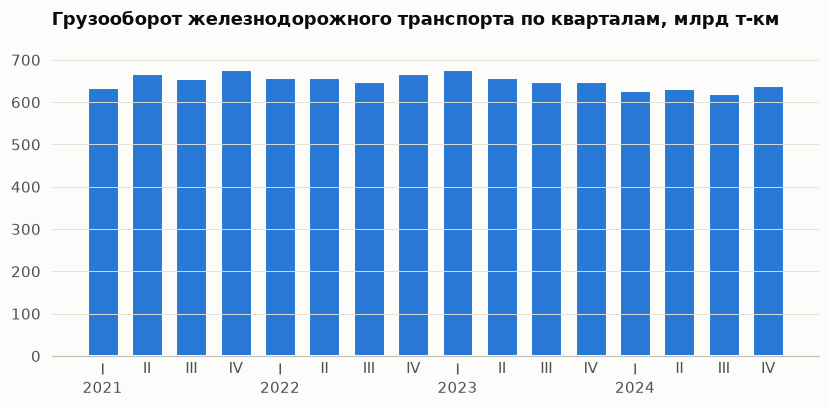

In [13]:
ROMAN = {1: "I", 2: "II", 3: "III", 4: "IV"}
labels = [f"{ROMAN[q]}\n{y}" if q == 1 else ROMAN[q]
          for y, q in zip(quarters.year, quarters.quarter)]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(range(len(quarters)), quarters.quarter_value, width=0.72, color=SERIES[0],
       edgecolor=SURFACE, linewidth=2)
ax.set_xticks(range(len(quarters)), labels)
ax.tick_params(axis="x", length=0)
ax.set_title("Грузооборот железнодорожного транспорта по кварталам, млрд т-км")
ax.set_ylim(0, quarters.quarter_value.max() * 1.12)
plt.show()

## 7. Любой показатель из таблиц выпусков

Ключевые ряды — малая часть бюллетеня. Таблица `table_values` содержит каждое число каждой
таблицы, около 95 тыс. значений: городской транспорт, порты, аварийность, тарифы и т. д.
Таблицу ищут по подписи (`caption`), строку — по `row_label`.

In [14]:
# самые частые темы таблиц по подписи (первые слова заголовка)
con.sql("""
    SELECT regexp_replace(caption, '^[0-9.]+\\s*', '') AS caption, count(DISTINCT document_id) AS issues
    FROM source_tables
    WHERE caption <> ''
    GROUP BY 1 ORDER BY issues DESC LIMIT 15
""").df()

,caption,issues
0,Коммерческий грузооборот по видам транспорта (миллиардов тонно-километров),29
1,Грузооборот по видам транспорта (миллиардов тонно-километров),29
2,Перевозки грузов по видам транспорта (миллионов тонн),29
3,Коммерческие перевозки грузов по видам транспорта (миллионов тонн),29
4,Пассажирооборот транспорта общего пользования (миллиардов пассажиро-километров),25
5,Перевозки пассажиров транспортом общего пользования (миллионов человек),25
6,"Индексы цен в отдельных секторах экономики на конец периода, в процентах",22
7,Объем перевозок грузов железнодорожным транспортом по видам грузов (млн. тонн),21
8,(рублей),20
9,(человек),20


In [15]:
con.sql("""
    SELECT report_period, col_period, value, unit, row_label
    FROM table_values
    WHERE caption ILIKE '%перевалки грузов в морских портах%'
      AND row_label ILIKE 'всего%' AND measure = 'value'
    ORDER BY report_period DESC, col_period DESC
    LIMIT 10
""").df()

,report_period,col_period,value,unit,row_label
0,2021-01..12,2021-01..12,835.2,млн т,Всего грузов
1,2021-01..12,2020-01..12,820.9,млн т,Всего грузов
2,2021-01..09,2021-01..09,621.6,млн т,Всего грузов
3,2021-01..09,2020-01..09,611.3,млн т,Всего грузов
4,2021-01..06,2021-01..06,412.1,млн т,Всего грузов
5,2021-01..06,2020-01..06,410.9,млн т,Всего грузов
6,2021-01..03,2021-01..03,198.1,млн т,Всего грузов
7,2021-01..03,2020-01..03,207.3,млн т,Всего грузов
8,2020-01..09,2020-01..09,611.5,млн т,Всего грузов
9,2020-01..09,2019-01..09,628.2,млн т,Всего грузов


## 8. Откуда взято число

Представление `values_with_source` связывает каждое значение с выпуском, файлом на сайте и
извлечённой таблицей. CSV таблицы лежит в `data/tables/`.

In [16]:
con.sql("""
    SELECT report_period, col_header, value_raw, issue_url, file_url, original_filename,
           v.table_id, t.csv_path
    FROM values_with_source v JOIN source_tables t USING (table_id)
    WHERE topic = 'freight_carried' AND mode = 'rail'
      AND col_period = '2024-01..12' AND measure = 'value'
""").df().T

,0
report_period,2024-01..12
col_header,Январь ‒ декабрь 2024 г.
value_raw,"1 183,9"
issue_url,https://mintrans.gov.ru/documents/7/14303
file_url,https://mintrans.gov.ru/file/528103
original_filename,Бюллетень - 2024.pdf
table_id,14303/528103:t006
csv_path,tables/14303_528103/t006.csv


## 9. Сверки

- `total_vs_sum` — итог против суммы видов транспорта в той же таблице;
- `revision` — одно значение в разных выпусках;
- `unit_suspect` — значение отличается в 100+ раз, вероятно другая единица.

In [17]:
con.sql("""
    SELECT "check", count(*) AS total, count(*) FILTER (NOT ok) AS failed
    FROM checks GROUP BY 1 ORDER BY 1
""").df()

,check,total,failed
0,revision,936,310
1,total_vs_sum,640,1
2,unit_suspect,2,2


In [18]:
con.sql("""
    SELECT "check", indicator, mode, period, expected, actual, diff_pct, table_id
    FROM checks WHERE NOT ok AND "check" <> 'revision'
""").df()

,check,indicator,mode,period,expected,actual,diff_pct,table_id
0,total_vs_sum,passenger_turnover,total_mintrans,2019-01..03,111.400,116.428,4.51,10010/431128:t003
1,unit_suspect,freight_carried,air,2023-01..06,0.211,211.000,99900.00,12787/496471:t006;13822/516389:t006
2,unit_suspect,freight_carried,air,2024-01..06,0.218,218.400,100083.49,13822/516389:t006;14772/543464:t005


In [19]:
# крупнейшие пересмотры между выпусками: смена состава и уточнения
con.sql("""
    SELECT indicator, mode, period, expected, actual, diff_pct
    FROM checks WHERE "check" = 'revision' AND NOT ok
    ORDER BY abs(diff_pct) DESC LIMIT 10
""").df()

,indicator,mode,period,expected,actual,diff_pct
0,freight_turnover,rail_industrial,2012-01..06,16.900,51.640,205.56
1,freight_turnover,rail_industrial,2012-01..09,25.400,77.400,204.72
2,freight_turnover,rail_industrial,2012-01..12,33.800,102.200,202.37
3,passenger_turnover,sea,2024-01..06,0.005,0.011,120.00
4,passenger_turnover,inland_water,2013-01..03,0.001,0.002,100.00
5,passenger_turnover,inland_water,2015-01..03,0.001,0.002,100.00
6,freight_carried,sea,2012-01..09,13.736,23.870,73.78
7,freight_turnover,sea,2024-01..03,11.373,19.600,72.34
8,passengers_carried,inland_water,2016-01..09,7.170,11.750,63.88
9,passengers_carried,inland_water,2017-01..09,6.790,11.080,63.18


## 10. Выгрузка

`COPY` пишет результат запроса в Parquet, CSV или JSON. Здесь — во временный каталог.

In [20]:
import tempfile

out = Path(tempfile.mkdtemp()) / "bulletin_series.parquet"
con.execute(f"COPY (SELECT * FROM series) TO '{out}' (FORMAT parquet)")
print(out.name, out.stat().st_size, "байт")
con.sql(f"SELECT indicator, count(*) AS rows FROM '{out}' GROUP BY ALL ORDER BY 1").df()

bulletin_series.parquet 20667 байт


,indicator,rows
0,freight_carried,503
1,freight_turnover,517
2,passenger_turnover,445
3,passengers_carried,447


In [21]:
con.close()